In [1]:
import pandas as pd
import numpy as np
import os
import joblib

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# 1. Cargar el dataset estandarizado y limpio
data_path = '../data/processed/cleaned_happiness.csv'
df = pd.read_csv(data_path)

print(f"✅ Dataset cargado correctamente: {df.shape[0]} filas, {df.shape[1]} columnas\n")

# 2. Definir variables de entrada (Features) y variable objetivo (Target)
features = ['gdp', 'family', 'health', 'freedom', 'generosity', 'corruption']
target = 'actual_happiness_score'

X = df[features]
y = df[target]

print("📌 Features seleccionadas:", features)
print("🎯 Variable objetivo (Target):", target)

# 3. División del dataset (70% Train, 30% Test)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, random_state=42
)

print(f"\n📊 Datos de entrenamiento (Train): {X_train.shape[0]} registros")
print(f"📊 Datos de prueba (Test): {X_test.shape[0]} registros\n")

# 4. Construir el Pipeline reproducible (StandardScaler + RandomForest)
model_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('regressor', RandomForestRegressor(n_estimators=100, random_state=42))
])

# 5. Entrenar el pipeline
print("⏳ Entrenando el modelo...")
model_pipeline.fit(X_train, y_train)

# 6. Evaluar
y_pred = model_pipeline.predict(X_test)
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print("\n=== MÉTRICAS DE EVALUACIÓN DEL MODELO ===")
print(f"MAE  (Mean Absolute Error): {mae:.4f}")
print(f"RMSE (Root Mean Squared Error): {rmse:.4f}")
print(f"R²   (R-Squared): {r2:.4f}\n")

# 7. Serializar y guardar el Pipeline completo (model.pkl)
os.makedirs('../models', exist_ok=True)
model_path = '../models/model.pkl'
joblib.dump(model_pipeline, model_path)

print(f"💾 Modelo serializado guardado exitosamente en: {model_path}")

✅ Dataset cargado correctamente: 782 filas, 9 columnas

📌 Features seleccionadas: ['gdp', 'family', 'health', 'freedom', 'generosity', 'corruption']
🎯 Variable objetivo (Target): actual_happiness_score

📊 Datos de entrenamiento (Train): 547 registros
📊 Datos de prueba (Test): 235 registros

⏳ Entrenando el modelo...

=== MÉTRICAS DE EVALUACIÓN DEL MODELO ===
MAE  (Mean Absolute Error): 0.4069
RMSE (Root Mean Squared Error): 0.5239
R²   (R-Squared): 0.7802

💾 Modelo serializado guardado exitosamente en: ../models/model.pkl


=== ESTADÍSTICAS DESCRIPTIVAS DE LAS FEATURES ===


,mean,std,min,50%,max
actual_happiness_score,5.379018,1.127456,2.693,5.322000,7.769000
gdp,0.916047,0.407340,0.000,0.982205,2.096000
family,1.078392,0.329548,0.000,1.124735,1.644000
health,0.612416,0.248309,0.000,0.647310,1.141000
freedom,0.411091,0.152880,0.000,0.431000,0.724000
generosity,0.218576,0.122321,0.000,0.201982,0.838075
corruption,0.125380,0.105760,0.000,0.090905,0.551910



=== MATRIZ DE CORRELACIÓN CON EL TARGET (actual_happiness_score) ===
actual_happiness_score    1.000000
gdp                       0.789284
health                    0.742456
family                    0.648799
freedom                   0.551258
corruption                0.397333
generosity                0.137578
Name: actual_happiness_score, dtype: float64


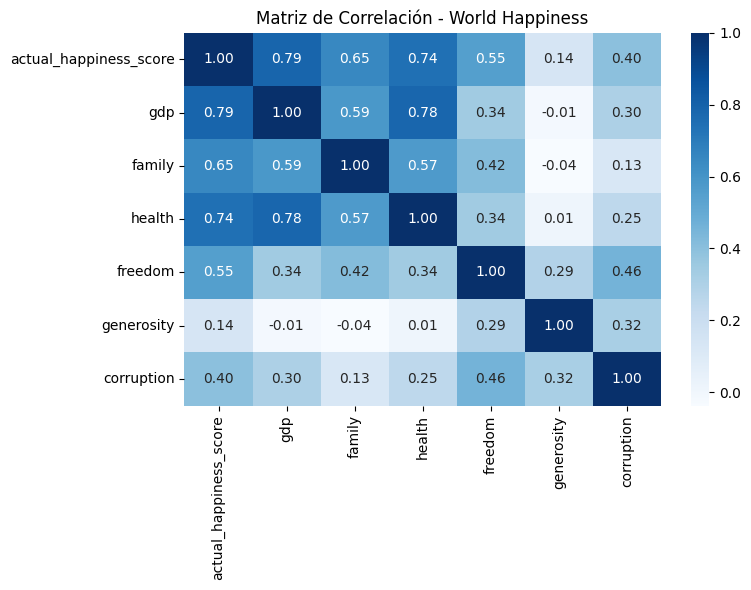

In [2]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

# 1. Cargar el dataset estandarizado
df = pd.read_csv('../data/processed/cleaned_happiness.csv')

# 2. Selección de columnas numéricas clave para análisis de relación
cols_to_analyze = ['actual_happiness_score', 'gdp', 'family', 'health', 'freedom', 'generosity', 'corruption']

print("=== ESTADÍSTICAS DESCRIPTIVAS DE LAS FEATURES ===")
display(df[cols_to_analyze].describe().T[['mean', 'std', 'min', '50%', 'max']])

print("\n=== MATRIZ DE CORRELACIÓN CON EL TARGET (actual_happiness_score) ===")
corr = df[cols_to_analyze].corr()
print(corr['actual_happiness_score'].sort_values(ascending=False))

# 3. Visualizar Mapa de Calor (Heatmap) de Correlación
plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, cmap='Blues', fmt='.2f')
plt.title('Matriz de Correlación - World Happiness')
plt.tight_layout()
plt.show()